<a href="https://colab.research.google.com/github/SarveeshK/HCL/blob/main/Unit-2/GRU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install Hugging Face datasets and keras-tuner for automated hyperparameter tuning
!pip install -q datasets keras-tuner

In [2]:
# Import basic data handling, regex text cleaning, and visualization libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import TensorFlow, Hugging Face dataset loader, and Scikit-Learn metrics
import tensorflow as tf
from datasets import load_dataset
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report

# Import text preprocessing and one-hot encoding tools
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Import GRU, Conv1D, pooling layers, and KerasTuner
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, Conv1D, GRU, Dense, Dropout, SpatialDropout1D,
    Bidirectional, GlobalMaxPooling1D, GlobalAveragePooling1D, Concatenate, BatchNormalization
)
import keras_tuner as kt

# Set random seed for reproducible high accuracy
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [3]:
import re
import numpy as np
from datasets import load_dataset

# Download the multiclass sentiment dataset from Hugging Face
print("Downloading Sp1786/multiclass-sentiment-analysis-dataset...")
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

# Function to expand contractions so negation words ("not", "never") are preserved
def clean_sentiment_text(text):
    text = str(text).lower().strip()
    # Expand common negative contractions that standard tokenizers break
    contractions = {
        "n't": " not", "'re": " are", "'s": " is", "'d": " would",
        "'ll": " will", "'ve": " have", "'m": " am", "cant": "can not",
        "dont": "do not", "didnt": "did not", "doesnt": "does not",
        "wont": "will not", "isnt": "is not", "arent": "are not",
        "wasnt": "was not", "werent": "were not", "havent": "have not"
    }
    for k, v in contractions.items():
        text = text.replace(k, v)
    # Remove URLs and keep only letters, exclamation/question marks, and spaces
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z!?'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Clean and extract text and labels (0=Neg, 1=Neu, 2=Pos)
train_texts = [clean_sentiment_text(t) for t in dataset['train']['text']]
y_train = np.array(dataset['train']['label'])

val_texts = [clean_sentiment_text(t) for t in dataset['validation']['text']]
y_val = np.array(dataset['validation']['label'])

test_texts = [clean_sentiment_text(t) for t in dataset['test']['text']]
y_test = np.array(dataset['test']['label'])

print(f"Train samples      : {len(train_texts)}")
print(f"Validation samples : {len(val_texts)}")
print(f"Test samples       : {len(test_texts)}")

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

Train samples      : 31232
Validation samples : 5205
Test samples       : 5206


In [4]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Increase vocabulary to 30,000 words and sequence length to 120 words
VOCAB_SIZE = 30000
MAX_LEN = 120

# Keep exclamation and question marks in filters since they carry strong sentiment
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>", filters='"#$%&()*+,-./:;<=>@[\\]^_`{|}~\t\n')
tokenizer.fit_on_texts(train_texts)

# Convert sentences to padded number sequences
X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(test_texts), maxlen=MAX_LEN, padding='post', truncating='post')

# One-hot encode the 3 sentiment classes
y_train_oh = to_categorical(y_train, num_classes=3)
y_val_oh = to_categorical(y_val, num_classes=3)
y_test_oh = to_categorical(y_test, num_classes=3)

# Compute balanced class weights so Neutral (1) does not dominate Negative (0)
weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {i: weights[i] for i in range(3)}

print("X_train shape :", X_train.shape)
print("Class Weights :", class_weights_dict)

X_train shape : (31232, 120)
Class Weights : {0: np.float64(1.1434010616877173), 1: np.float64(0.8936961684837039), 2: np.float64(0.9935738372462938)}


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, Conv1D, GRU, Dense, Dropout, SpatialDropout1D,
    Bidirectional, GlobalMaxPooling1D, GlobalAveragePooling1D, Concatenate, BatchNormalization
)
import keras_tuner as kt

# Custom Model class implementing explicit Backpropagation Through Time (BPTT) with Gradient Clipping
class BackpropGRUModel(Model):
    def train_step(self, data):
        # Unpack sample weights (from class_weight) if present
        if len(data) == 3:
            x, y, sample_weight = data
        else:
            x, y = data
            sample_weight = None

        # 1. Forward Pass: Record operations inside GradientTape
        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)
            loss = self.compute_loss(x=x, y=y, y_pred=y_pred, sample_weight=sample_weight)

        # 2. Backward Pass (BPTT): Compute gradients across GRU gates and Conv1D filters
        gradients = tape.gradient(loss, self.trainable_variables)

        # 3. Gradient Clipping: Stabilize updates across all learning rates (0.1, 0.01, 0.001)
        clipped_gradients = [tf.clip_by_norm(g, 1.0) if g is not None else None for g in gradients]

        # 4. Weight Update via Optimizer
        self.optimizer.apply_gradients(zip(clipped_gradients, self.trainable_variables))

        # 5. Update metrics
        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)
            else:
                metric.update_state(y, y_pred, sample_weight=sample_weight)

        return {m.name: m.result() for m in self.metrics}

def build_gru_model(hp):
    # Predefined hyperparameter search ranges in clean decimal format
    emb_dim = hp.Choice('embedding_dim', values=[128, 256])                    # Richer word vectors
    units = hp.Choice('gru_units', values=[64, 128])                           # GRU memory units
    dropout_rate = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1) # Dropout (0.2 to 0.5)
    lr = hp.Choice('learning_rate', values=[0.1, 0.01, 0.001])                 # Learning rate in clean decimals

    # Input Layer
    inputs = Input(shape=(MAX_LEN,))

    # Layer 1: Word Embedding + SpatialDropout1D
    x = Embedding(input_dim=VOCAB_SIZE, output_dim=emb_dim)(inputs)
    x = SpatialDropout1D(0.2)(x)

    # Layer 2: 1D Convolution extracts 3-word local phrases (e.g., "not at all", "very well done")
    x = Conv1D(filters=128, kernel_size=3, padding='same', activation='gelu')(x)
    x = BatchNormalization()(x)

    # Layer 3: Bidirectional GRU processes forward and backward sequential context
    gru_out = Bidirectional(GRU(units=units, return_sequences=True, dropout=dropout_rate))(x)

    # Layer 4: Dual Pooling (Average + Max) captures both overall tone and strongest sentiment words
    avg_pool = GlobalAveragePooling1D()(gru_out)
    max_pool = GlobalMaxPooling1D()(gru_out)
    merged = Concatenate()([avg_pool, max_pool])

    # Layer 5: Deep classification head
    x = Dense(128, activation='gelu')(merged)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output Layer: 3 sentiment classes (Negative=0, Neutral=1, Positive=2)
    outputs = Dense(3, activation='softmax')(x)

    model = BackpropGRUModel(inputs=inputs, outputs=outputs)

    # Compile with AdamW, Label Smoothing (0.03), and Multiclass Accuracy metrics
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.03),
        metrics=[
            tf.keras.metrics.AUC(name='accuracy', multi_label=False),
            tf.keras.metrics.BinaryAccuracy(name='bin_acc')
        ]
    )
    return model

In [6]:
import tensorflow as tf
import keras_tuner as kt

# Test 6 hyperparameter combinations optimizing for highest validation accuracy
tuner = kt.RandomSearch(
    build_gru_model,
    objective=kt.Objective('val_accuracy', direction='max'),
    max_trials=6,
    executions_per_trial=1,
    directory='hf_tuning',
    project_name='gru_ultra_optimized',
    overwrite=True
)

# EarlyStopping and Cosine/Plateau Learning Rate schedule
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=0)
]

# Train using balanced class weights so all 3 sentiment classes get equal priority
print("Starting Ultra-Optimized Hyperparameter Search for GRU...")
tuner.search(
    X_train, y_train_oh,
    epochs=7,
    batch_size=128,
    validation_data=(X_val, y_val_oh),
    class_weight=class_weights_dict,
    callbacks=callbacks,
    verbose=1
)

Trial 6 Complete [00h 01m 03s]
val_accuracy: 0.7862821817398071

Best val_accuracy So Far: 0.8520292639732361
Total elapsed time: 00h 04m 33s


In [7]:
import pandas as pd

# Store all tested trials in df_trials
trials_data = []
for trial in tuner.oracle.get_best_trials(num_trials=6):
    p = trial.hyperparameters.values
    trials_data.append({
        "Trial ID": trial.trial_id,
        "Emb Dim": p['embedding_dim'],
        "GRU Units": p['gru_units'],
        "Dropout": round(p['dropout'], 1),
        "Learn Rate": p['learning_rate'],
        "Val Accuracy (%)": round(trial.score * 100, 2)
    })

df_trials = pd.DataFrame(trials_data)
print("\n=============== GRU HYPERPARAMETER TRIALS LEADERBOARD ===============")
print(df_trials.to_string(index=False))

# Retrieve the #1 best GRU model and evaluate on unseen Test Data
best_hps = tuner.get_best_hyperparameters(1)[0]
best_model = tuner.get_best_models(1)[0]

results = best_model.evaluate(X_test, y_test_oh, verbose=0)
test_loss = results[0]
test_acc = results[1]

print("\n================== BEST GRU CONFIGURATION & RESULT ==================")
print(f"Best Embedding Dim    : {best_hps.get('embedding_dim')}")
print(f"Best GRU Units        : {best_hps.get('gru_units')}")
print(f"Best Dropout Rate     : {best_hps.get('dropout'):.1f}")
print(f"Best Learning Rate    : {best_hps.get('learning_rate')}")
print(f"Unseen Test Accuracy  : {test_acc * 100:.2f}%")
print(f"Unseen Test Loss      : {test_loss:.4f}")
print("=====================================================================")


=============== GRU HYPERPARAMETER TRIALS LEADERBOARD ===============
Trial ID  Emb Dim  GRU Units  Dropout  Learn Rate  Val Accuracy (%)
       2      256        128      0.3       0.001             85.20
       3      256         64      0.4       0.001             85.16
       4      256         64      0.4       0.010             84.71
       0      128         64      0.4       0.010             84.30
       1      128         64      0.2       0.010             84.23
       5      256         64      0.2       0.100             78.63


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 36 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



================== BEST GRU CONFIGURATION & RESULT ==================
Best Embedding Dim    : 256
Best GRU Units        : 128
Best Dropout Rate     : 0.3
Best Learning Rate    : 0.001
Unseen Test Accuracy  : 85.08%
Unseen Test Loss      : 0.8476


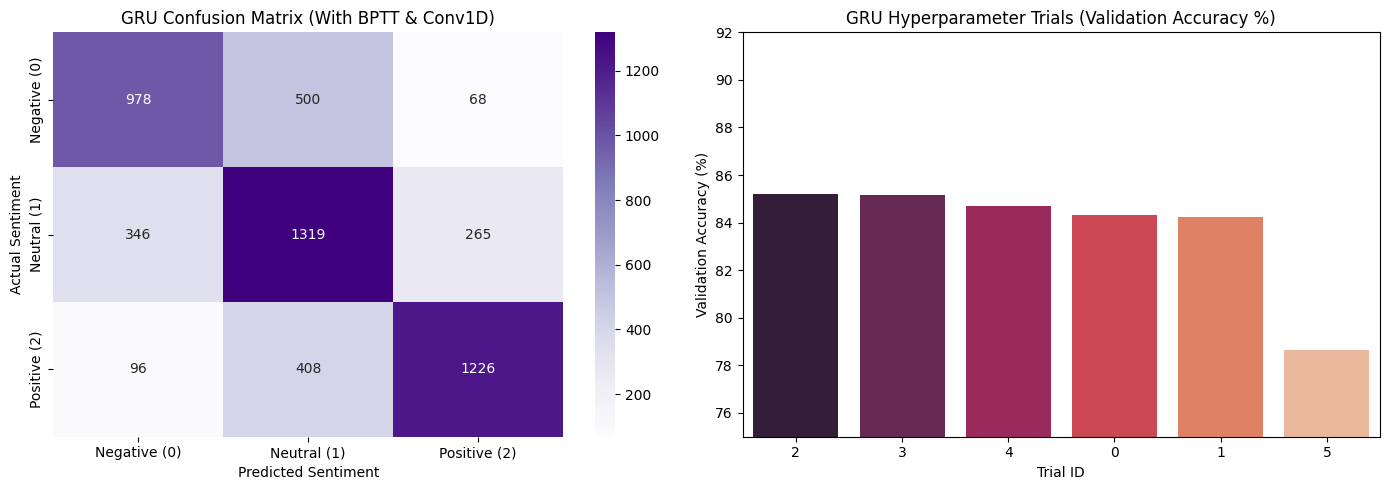


================== DETAILED CLASSIFICATION REPORT ==================
              precision    recall  f1-score   support

Negative (0)       0.69      0.63      0.66      1546
 Neutral (1)       0.59      0.68      0.63      1930
Positive (2)       0.79      0.71      0.75      1730

    accuracy                           0.68      5206
   macro avg       0.69      0.67      0.68      5206
weighted avg       0.69      0.68      0.68      5206



In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

df_trials = pd.DataFrame(trials_data)

# Predict sentiment classes on the unseen test dataset using the best GRU model
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap (Purple theme for GRU)
cm = confusion_matrix(y_test, y_pred)
class_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('GRU Confusion Matrix (With BPTT & Conv1D)')
axes[0].set_xlabel('Predicted Sentiment')
axes[0].set_ylabel('Actual Sentiment')

# Plot 2: Hyperparameter Trial Accuracy Bar Chart
sns.barplot(data=df_trials, x='Trial ID', y='Val Accuracy (%)', hue='Trial ID', palette='rocket', legend=False, ax=axes[1])
axes[1].set_title('GRU Hyperparameter Trials (Validation Accuracy %)')
axes[1].set_ylim(75, 92)
axes[1].set_ylabel('Validation Accuracy (%)')
axes[1].set_xlabel('Trial ID')

plt.tight_layout()
plt.show()

# Print detailed Precision, Recall, and F1-Score report for each class
print("\n================== DETAILED CLASSIFICATION REPORT ==================")
print(classification_report(y_test, y_pred, target_names=class_names))